# Exploratory data analysis — synthetic Fmax dataset
Inputs are restricted to the PRD §5.4 allowlist; leakage columns appear here only for context.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from fmax import config as C
from fmax.data import load_raw, validate, split
df = load_raw(C.DATA_PATH)
rep = validate(df); rep.to_dict()

{'n_rows': 6000,
 'n_cols': 25,
 'missing_values': {},
 'duplicate_rows': 0,
 'duplicate_unit_ids': 0,
 'split_counts': {'test': 4000, 'train': 1500, 'calibration': 500},
 'outliers_iqr': {'ro_03': 1, 'ro_09': 1},
 'warnings': [],
 'ok': True}

## Split sizes and target distribution

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
calibration,500.0,1991.356400,104.735715,1725.7,1917.125,1989.40,2061.325,2259.4
test,4000.0,1989.894175,104.093898,1616.0,1919.100,1990.05,2059.150,2329.5
train,1500.0,1982.902733,101.520659,1663.1,1912.575,1982.15,2047.975,2281.2


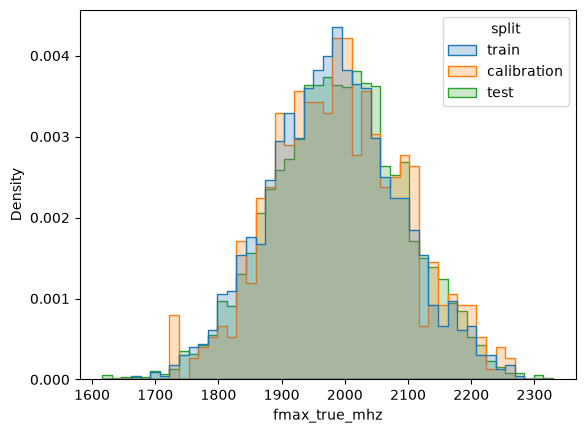

In [2]:
display(df.groupby('split')[C.TARGET].describe())
sns.histplot(df, x=C.TARGET, hue='split', element='step', stat='density', common_norm=False);

## Feature distributions

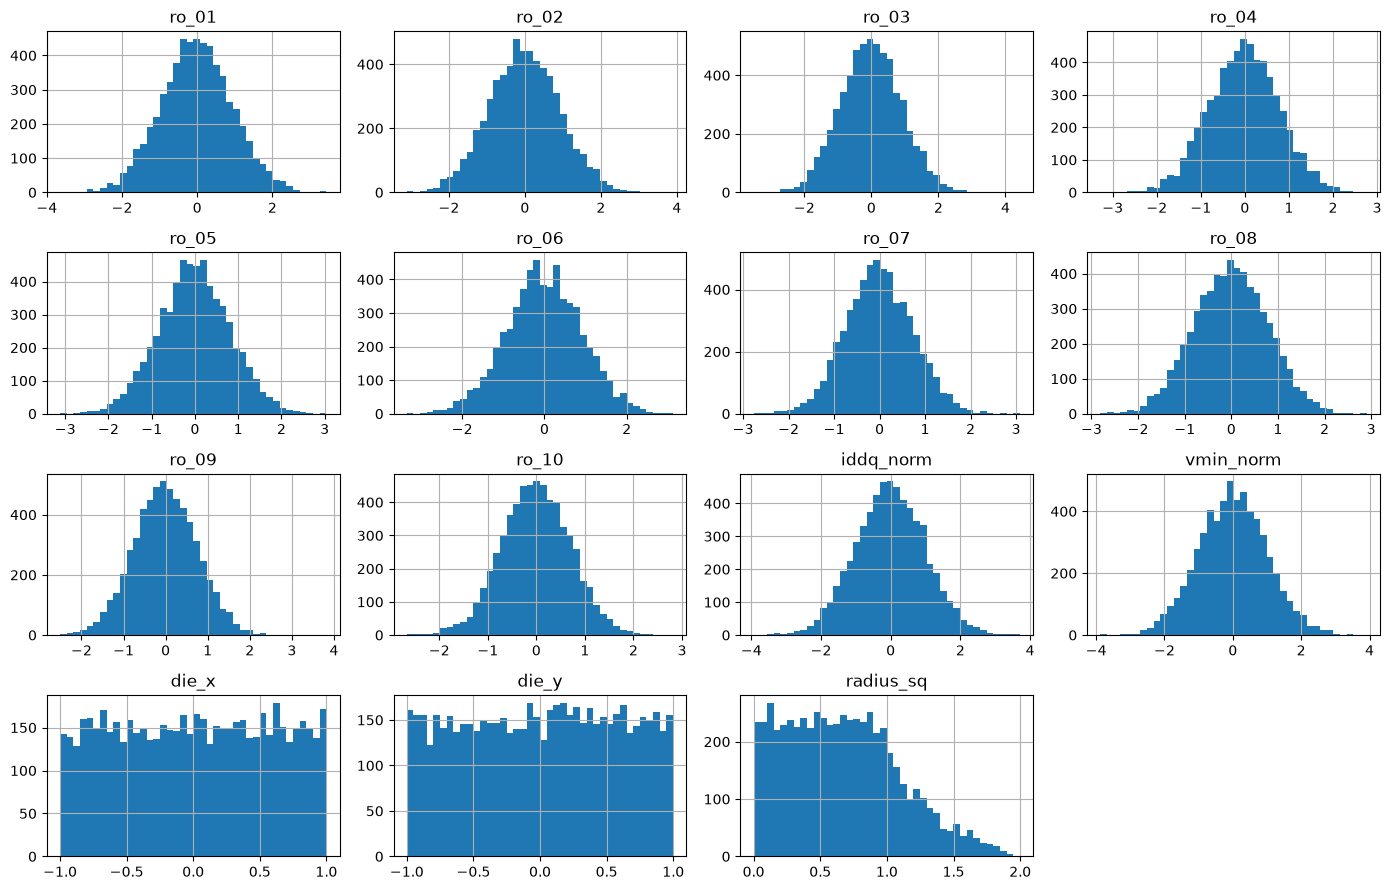

In [3]:
df[C.FEATURES].hist(bins=40, figsize=(14, 9)); plt.tight_layout()

## Correlation with Fmax (training split only)

vmin_norm   -0.571167
radius_sq   -0.078399
die_x       -0.018341
die_y        0.032194
iddq_norm    0.765649
ro_10        0.848453
ro_07        0.859101
ro_09        0.869149
ro_04        0.878150
ro_08        0.883620
ro_05        0.886220
ro_06        0.902390
ro_01        0.904627
ro_03        0.906288
ro_02        0.906336
Name: fmax_true_mhz, dtype: float64

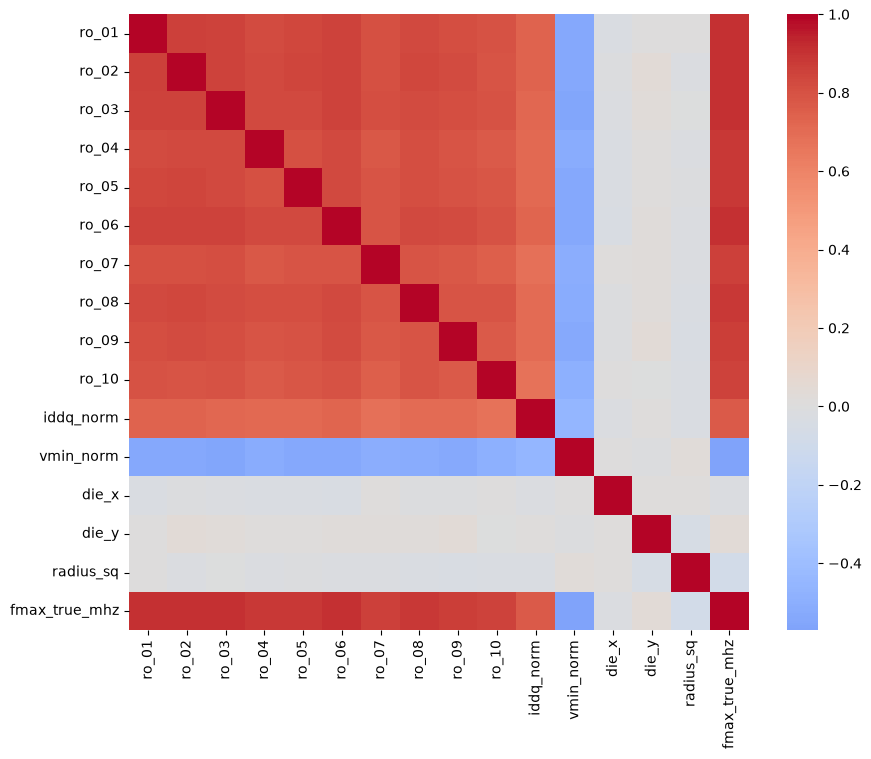

In [4]:
tr = split(df)['train']
corr = tr[C.FEATURES + [C.TARGET]].corr()
plt.figure(figsize=(10, 8)); sns.heatmap(corr, cmap='coolwarm', center=0)
corr[C.TARGET].drop(C.TARGET).sort_values()

## Ring-oscillator mean vs Fmax
The 10 RO readings are noisy views of one latent speed term; their mean is the strongest single predictor.

C:\Users\lebha\AppData\Local\Temp\ipykernel_32716\2145643425.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tr = tr.assign(ro_mean=tr[C.RO_COLS].mean(1))


corr(ro_mean, Fmax) = 0.969


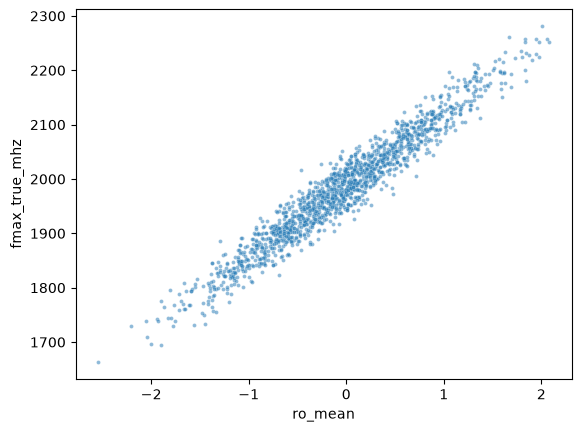

In [5]:
tr = tr.assign(ro_mean=tr[C.RO_COLS].mean(1))
sns.scatterplot(tr, x='ro_mean', y=C.TARGET, s=8, alpha=.5)
print('corr(ro_mean, Fmax) =', tr[['ro_mean', C.TARGET]].corr().iloc[0, 1].round(3))

## Wafer position

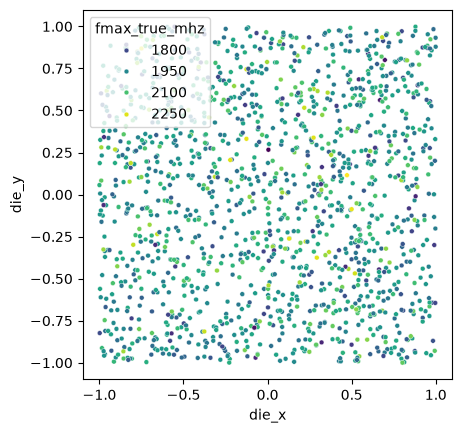

In [6]:
sns.scatterplot(tr, x='die_x', y='die_y', hue=C.TARGET, palette='viridis', s=12)
plt.gca().set_aspect('equal')

## Speed-bin mix and conventional search cost (supplied columns, context only)

In [7]:
display(df['true_bin_mhz'].value_counts())
df[['tests_binary', 'tests_windowed']].describe()

true_bin_mhz
1900      2070
2000      1885
1800       998
2100       726
reject     202
2200       119
Name: count, dtype: int64

,tests_binary,tests_windowed
count,6000.000000,6000.000000
mean,6.450833,3.786167
std,0.497618,1.366048
min,6.000000,3.000000
25%,6.000000,3.000000
50%,6.000000,3.000000
75%,7.000000,4.000000
max,7.000000,11.000000
